# Problema 3 — Rede CNN em PyTorch para Classificação de Uso e Cobertura do Solo (EuroSAT)

**Dataset:** EuroSAT RGB (27.000 imagens de satélite Sentinel-2, $64 \times 64$ pixels, 10 classes).

In [1]:
import copy
import ssl
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import EuroSAT
from torchvision.transforms import v2 as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})
print(f"Dispositivo: {DEVICE}")

Dispositivo: cuda


## 1. Preparação dos Dados

- Carregamento do EuroSAT RGB, contagem por classe e grade $10 \times 5$ de amostras.
- Divisão estratificada 70% treino / 15% validação / 15% teste com semente fixa (`42`).
- Conversão para tensores em $[0, 1]$ e normalização *Z-score* por canal (R, G, B) usando **apenas** a média e o desvio-padrão do treino.
- `DataLoader` com *mini-batches* de tamanho 64, embaralhando somente o treino.

  0%|          | 0.00/94.3M [00:00<?, ?B/s]

  0%|          | 32.8k/94.3M [00:00<15:10, 104kB/s]

 19%|█▊        | 17.6M/94.3M [00:00<00:01, 54.8MB/s]

 35%|███▍      | 32.7M/94.3M [00:00<00:00, 84.2MB/s]

 52%|█████▏    | 48.8M/94.3M [00:00<00:00, 107MB/s] 

 67%|██████▋   | 63.6M/94.3M [00:00<00:00, 120MB/s]

 84%|████████▎ | 78.9M/94.3M [00:00<00:00, 130MB/s]

 99%|█████████▉| 93.5M/94.3M [00:00<00:00, 133MB/s]

100%|██████████| 94.3M/94.3M [00:00<00:00, 101MB/s]

,Imagens,Proporcao
AnnualCrop,3000,11.11
Forest,3000,11.11
HerbaceousVegetation,3000,11.11
Highway,2500,9.26
Industrial,2500,9.26
Pasture,2000,7.41
PermanentCrop,2500,9.26
Residential,3000,11.11
River,2500,9.26
SeaLake,3000,11.11


Total: 27000 | Mín: 2000 | Máx: 3000 | Razão máx/mín: 1.50x


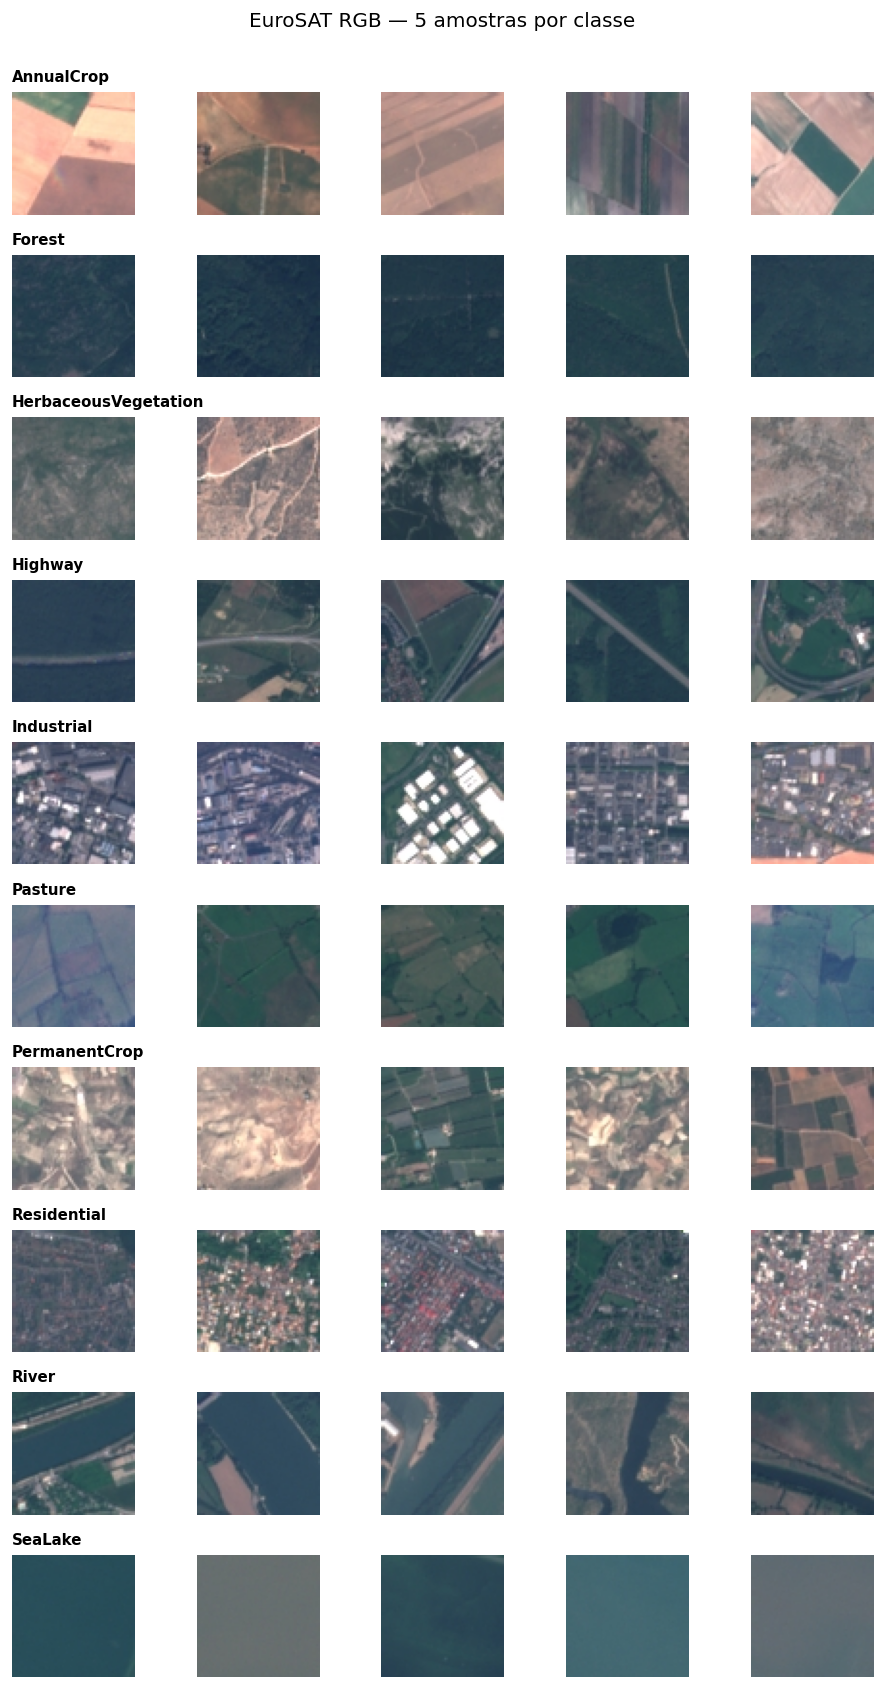

In [2]:
ssl._create_default_https_context = ssl._create_unverified_context
raw_ds = EuroSAT(root="data/eurosat", download=True)
classes = raw_ds.classes
targets = np.array(raw_ds.targets)

# Distribuição de classes
counts = pd.Series(targets).value_counts().sort_index()
counts.index = classes
display(counts.to_frame("Imagens").assign(Proporcao=lambda d: (d["Imagens"] / len(targets) * 100).round(2)))
print(f"Total: {len(targets)} | Mín: {counts.min()} | Máx: {counts.max()} | Razão máx/mín: {counts.max()/counts.min():.2f}x")

# Grade com 5 imagens por classe
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(classes), 5, figsize=(8, 14))
for row, cls_idx in enumerate(range(len(classes))):
    idxs = rng.choice(np.where(targets == cls_idx)[0], size=5, replace=False)
    for col, idx in enumerate(idxs):
        img, _ = raw_ds[idx]
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(classes[cls_idx], loc="left", fontsize=9, fontweight="bold")
plt.suptitle("EuroSAT RGB — 5 amostras por classe", y=1.002, fontsize=12)
plt.tight_layout()
plt.show()

In [3]:
# Pré-carregamento em tensor uint8 (27000 x 3 x 64 x 64 ~ 331 MB) para eliminar gargalo de disco
t0 = time.time()
imgs_u8 = torch.empty((len(raw_ds), 3, 64, 64), dtype=torch.uint8)
for i in range(len(raw_ds)):
    arr = np.asarray(raw_ds[i][0], dtype=np.uint8)
    imgs_u8[i] = torch.from_numpy(arr).permute(2, 0, 1)
labels_t = torch.tensor(targets, dtype=torch.long)
print(f"Imagens carregadas em RAM em {time.time() - t0:.1f}s | shape={tuple(imgs_u8.shape)}")

# Divisão estratificada 70% treino / 15% validação / 15% teste
all_idx = np.arange(len(raw_ds))
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=SEED)
print(f"Split -> Treino: {len(train_idx)} | Validação: {len(val_idx)} | Teste: {len(test_idx)}")

# Média e desvio-padrão por canal calculados apenas no treino (em escala [0, 1])
train_f = imgs_u8[train_idx].float().div_(255.0)
mean = train_f.mean(dim=(0, 2, 3))
std = train_f.std(dim=(0, 2, 3))
del train_f
print(f"Estatísticas do treino -> mean={mean.tolist()} | std={std.tolist()}")

class TensorImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        x = self.images[idx]
        if self.transform is not None:
            x = self.transform(x)
        return x, self.labels[idx]

eval_tf = T.Compose([T.ToDtype(torch.float32, scale=True), T.Normalize(mean.tolist(), std.tolist())])
aug_tf = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=30),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean.tolist(), std.tolist()),
])

BATCH_SIZE = 64
def make_loaders(train_tf):
    g = torch.Generator().manual_seed(SEED)
    tr = DataLoader(TensorImageDataset(imgs_u8[train_idx], labels_t[train_idx], train_tf), batch_size=BATCH_SIZE, shuffle=True, generator=g)
    va = DataLoader(TensorImageDataset(imgs_u8[val_idx], labels_t[val_idx], eval_tf), batch_size=BATCH_SIZE, shuffle=False)
    te = DataLoader(TensorImageDataset(imgs_u8[test_idx], labels_t[test_idx], eval_tf), batch_size=BATCH_SIZE, shuffle=False)
    return tr, va, te

/tmp/ipykernel_919/2935013352.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  imgs_u8[i] = torch.from_numpy(arr).permute(2, 0, 1)


Imagens carregadas em RAM em 9.4s | shape=(27000, 3, 64, 64)
Split -> Treino: 18900 | Validação: 4050 | Teste: 4050


Estatísticas do treino -> mean=[0.34390127658843994, 0.37995365262031555, 0.40755072236061096] | std=[0.20242461562156677, 0.13668294250965118, 0.11540833860635757]


## 2. Topologia da CNN

Três blocos `Conv2d(3×3, stride=1, padding=1) → ReLU → MaxPool2d(2×2, stride=2)` com 32, 64 e 128 filtros, seguidos de `Flatten → Linear(8192, 128) → ReLU → Linear(128, 10)` (sem softmax).

In [4]:
class EuroSATCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def eval_epoch(model, loader, criterion):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    preds_all, labels_all = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss_sum += criterion(logits, yb).item() * len(xb)
            preds = logits.argmax(dim=1)
            correct += (preds == yb).sum().item()
            total += len(xb)
            preds_all.append(preds.cpu().numpy())
            labels_all.append(yb.cpu().numpy())
    return loss_sum / total, correct / total, np.concatenate(preds_all), np.concatenate(labels_all)


def train_cnn(train_loader, val_loader, epochs=30, lr=1e-3, tag="CNN"):
    torch.manual_seed(SEED)
    model = EuroSATCNN(len(classes)).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}
    best_val, best_epoch, best_state = float("inf"), 0, None
    t0 = time.time()

    for ep in range(1, epochs + 1):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(xb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(xb)

        tr_loss, tr_acc = loss_sum / total, correct / total
        va_loss, va_acc, _, _ = eval_epoch(model, val_loader, criterion)
        hist["tr_loss"].append(tr_loss); hist["va_loss"].append(va_loss)
        hist["tr_acc"].append(tr_acc);   hist["va_acc"].append(va_acc)

        if va_loss < best_val:
            best_val, best_epoch = va_loss, ep
            best_state = copy.deepcopy(model.state_dict())

        if ep in (1, 10, 20, 30) or ep == best_epoch:
            print(f"[{tag}] Ep {ep:02d}/{epochs} | tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | va_loss={va_loss:.4f} va_acc={va_acc:.4f}")

    print(f"[{tag}] Concluído em {time.time()-t0:.1f}s | Melhor época: {best_epoch} (val_loss={best_val:.4f})\n")
    model.load_state_dict(best_state)
    return model, hist, best_epoch, best_val


def plot_curves(hist, best_epoch, title):
    ep = range(1, len(hist["tr_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(ep, hist["tr_loss"], label="Treino", lw=1.8)
    axes[0].plot(ep, hist["va_loss"], label="Validação", lw=1.8)
    axes[0].axvline(best_epoch, color="crimson", ls="--", alpha=0.8, label=f"Melhor época ({best_epoch})")
    axes[0].set(title=f"{title} — Loss", xlabel="Época", ylabel="CrossEntropyLoss")
    axes[0].legend()

    axes[1].plot(ep, hist["tr_acc"], label="Treino", lw=1.8)
    axes[1].plot(ep, hist["va_acc"], label="Validação", lw=1.8)
    axes[1].axvline(best_epoch, color="crimson", ls="--", alpha=0.8, label=f"Melhor época ({best_epoch})")
    axes[1].set(title=f"{title} — Acurácia", xlabel="Época", ylabel="Acurácia")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def evaluate_test(model, test_loader, title):
    _, _, y_pred, y_true = eval_epoch(model, test_loader, nn.CrossEntropyLoss())
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    cm = confusion_matrix(y_true, y_pred)

    metrics_df = pd.DataFrame({"Classe": classes, "Precisão": p, "Recall": r, "F1-score": f1})
    metrics_df.loc[len(metrics_df)] = ["Média Macro", p_m, r_m, f1_m]
    print(f"{title} -> Acurácia Global: {acc:.4f} | F1 Macro: {f1_m:.4f}")
    display(metrics_df.round(4))

    fig, ax = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set(title=f"Matriz de Confusão — {title}", xlabel="Predito", ylabel="Real")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    # Pares de classes mais confundidos (soma simétrica i<->j)
    pairs = []
    for i in range(len(classes)):
        for j in range(i + 1, len(classes)):
            total_err = int(cm[i, j] + cm[j, i])
            pairs.append((total_err, classes[i], classes[j], int(cm[i, j]), int(cm[j, i]), i, j))
    pairs.sort(reverse=True)
    return {"acc": acc, "p_macro": p_m, "r_macro": r_m, "f1_macro": f1_m, "cm": cm, "pairs": pairs, "y_true": y_true, "y_pred": y_pred}

## 3 e 4. Treinamento sem *Data Augmentation* e Avaliação no Conjunto de Teste

[Sem Aug] Ep 01/30 | tr_loss=0.9388 tr_acc=0.6581 | va_loss=0.6949 va_acc=0.7565


[Sem Aug] Ep 02/30 | tr_loss=0.5611 tr_acc=0.7997 | va_loss=0.5336 va_acc=0.8096


[Sem Aug] Ep 03/30 | tr_loss=0.4188 tr_acc=0.8541 | va_loss=0.4455 va_acc=0.8462


[Sem Aug] Ep 04/30 | tr_loss=0.3417 tr_acc=0.8815 | va_loss=0.4311 va_acc=0.8472


[Sem Aug] Ep 05/30 | tr_loss=0.2709 tr_acc=0.9047 | va_loss=0.3737 va_acc=0.8704


[Sem Aug] Ep 06/30 | tr_loss=0.2303 tr_acc=0.9182 | va_loss=0.3632 va_acc=0.8790


[Sem Aug] Ep 10/30 | tr_loss=0.0806 tr_acc=0.9739 | va_loss=0.3972 va_acc=0.8941


[Sem Aug] Ep 20/30 | tr_loss=0.0272 tr_acc=0.9921 | va_loss=0.4961 va_acc=0.9010


[Sem Aug] Ep 30/30 | tr_loss=0.0087 tr_acc=0.9975 | va_loss=0.8454 va_acc=0.8686
[Sem Aug] Concluído em 170.6s | Melhor época: 6 (val_loss=0.3632)



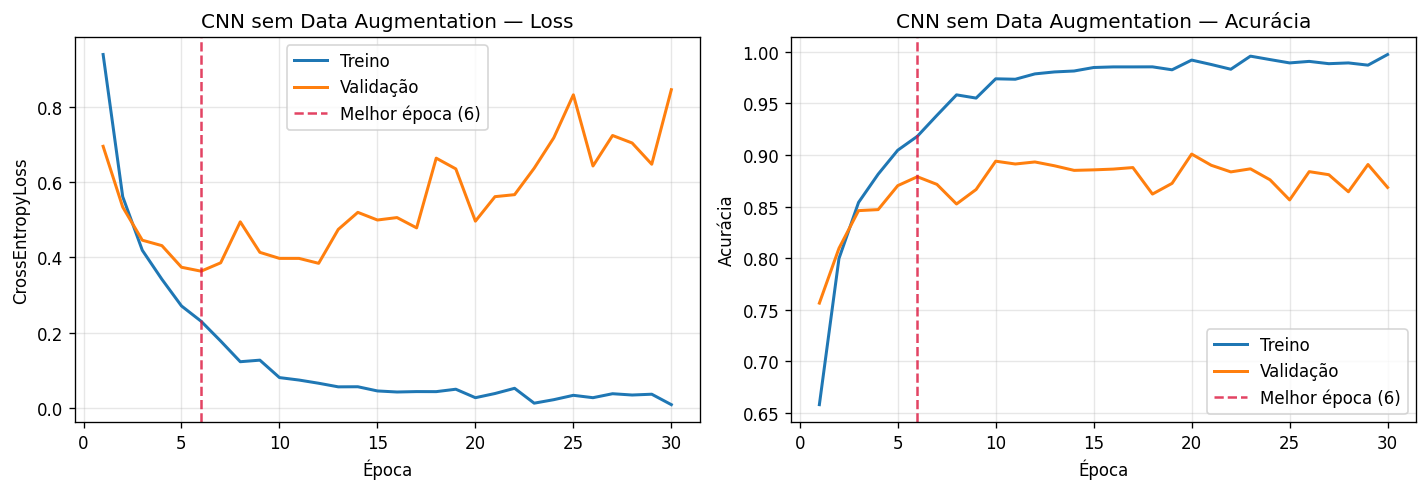

CNN sem Data Augmentation -> Acurácia Global: 0.8909 | F1 Macro: 0.8877


,Classe,Precisão,Recall,F1-score
0,AnnualCrop,0.8761,0.8956,0.8857
1,Forest,0.9528,0.9422,0.9475
2,HerbaceousVegetation,0.8788,0.8378,0.8578
3,Highway,0.8647,0.7840,0.8224
4,Industrial,0.8789,0.9680,0.9213
5,Pasture,0.8289,0.9367,0.8795
6,PermanentCrop,0.7896,0.8107,0.8000
7,Residential,0.9461,0.9756,0.9606
8,River,0.8672,0.8533,0.8602
9,SeaLake,0.9926,0.8956,0.9416


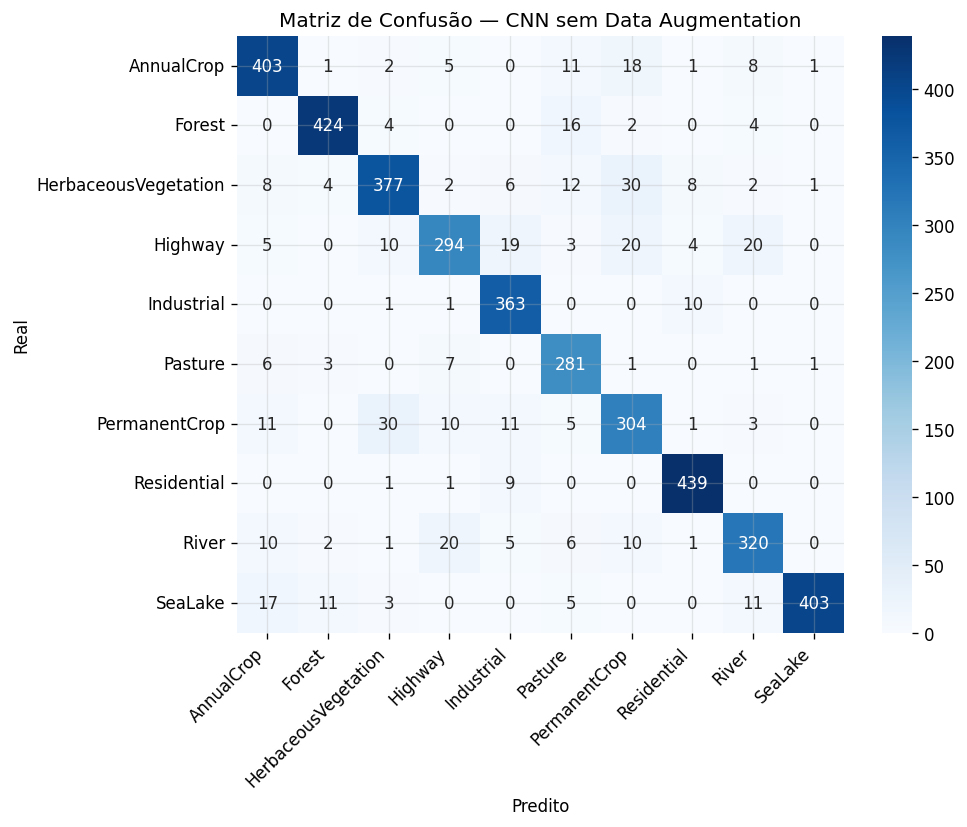

Top 3 pares mais confundidos (Sem Data Augmentation):
  HerbaceousVegetation <-> PermanentCrop: 60 erros (HerbaceousVegetation->PermanentCrop: 30, PermanentCrop->HerbaceousVegetation: 30)
  Highway <-> River: 40 erros (Highway->River: 20, River->Highway: 20)
  Highway <-> PermanentCrop: 30 erros (Highway->PermanentCrop: 20, PermanentCrop->Highway: 10)


In [5]:
tr_loader_base, va_loader, te_loader = make_loaders(eval_tf)
model_base, hist_base, best_ep_base, best_val_base = train_cnn(tr_loader_base, va_loader, epochs=30, lr=1e-3, tag="Sem Aug")
plot_curves(hist_base, best_ep_base, "CNN sem Data Augmentation")
res_base = evaluate_test(model_base, te_loader, "CNN sem Data Augmentation")

print("Top 3 pares mais confundidos (Sem Data Augmentation):")
top3_pairs = res_base["pairs"][:3]
for total_err, c1, c2, e12, e21, _, _ in top3_pairs:
    print(f"  {c1} <-> {c2}: {total_err} erros ({c1}->{c2}: {e12}, {c2}->{c1}: {e21})")

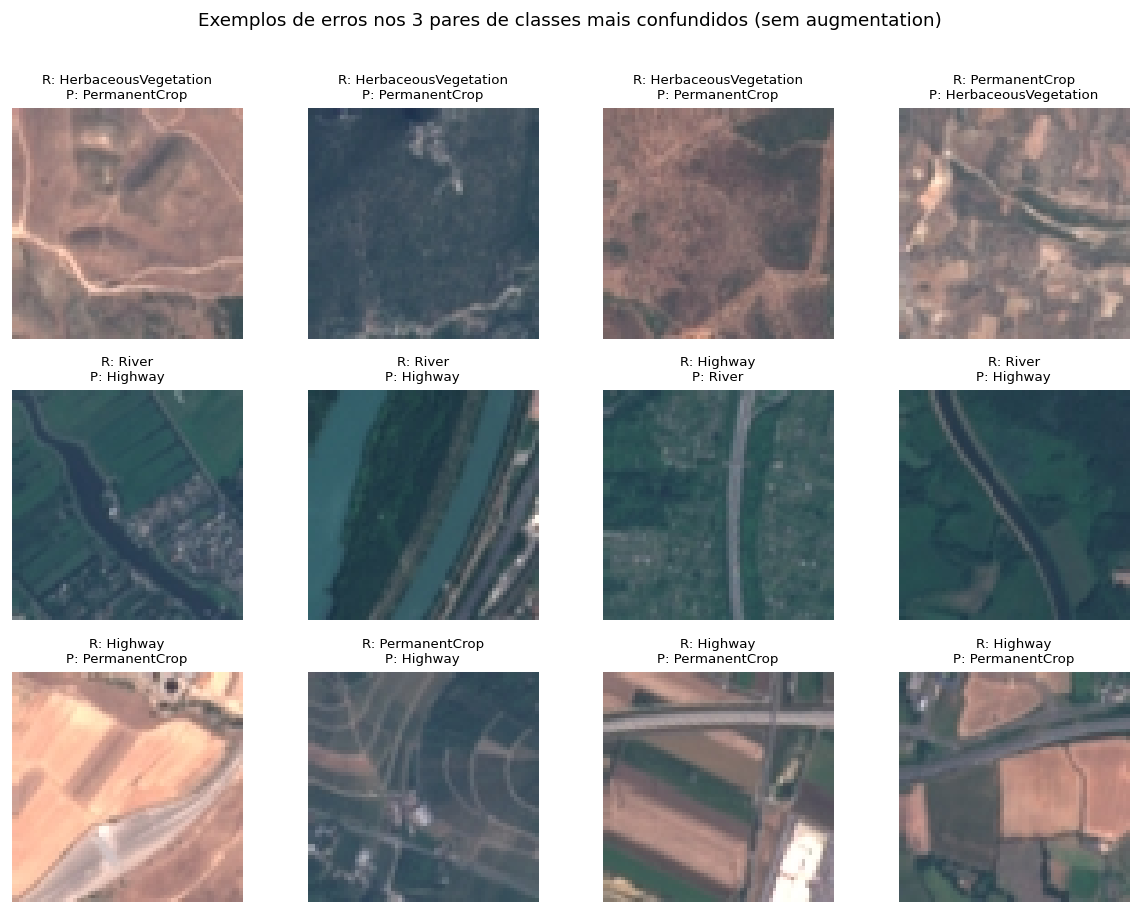

In [6]:
# Exemplos visuais de imagens classificadas incorretamente nos 3 pares mais confundidos
y_true, y_pred = res_base["y_true"], res_base["y_pred"]
fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for row, (_, c1, c2, _, _, i1, i2) in enumerate(top3_pairs):
    err_mask = ((y_true == i1) & (y_pred == i2)) | ((y_true == i2) & (y_pred == i1))
    err_pos = np.where(err_mask)[0][:4]
    for col in range(4):
        ax = axes[row, col]
        if col < len(err_pos):
            pos = err_pos[col]
            img = imgs_u8[test_idx[pos]].permute(1, 2, 0).numpy()
            ax.imshow(img)
            ax.set_title(f"R: {classes[y_true[pos]]}\nP: {classes[y_pred[pos]]}", fontsize=8)
        ax.axis("off")
plt.suptitle("Exemplos de erros nos 3 pares de classes mais confundidos (sem augmentation)", y=1.01, fontsize=11)
plt.tight_layout()
plt.show()

## 5. Treinamento com *Data Augmentation* e Comparação Final

Mesma topologia, mesmos hiperparâmetros e mesmo critério de parada antecipada, aplicando `RandomHorizontalFlip`, `RandomVerticalFlip` e `RandomRotation(30)` **apenas** no conjunto de treino.

[Com Aug] Ep 01/30 | tr_loss=1.0118 tr_acc=0.6288 | va_loss=0.7917 va_acc=0.7163


[Com Aug] Ep 02/30 | tr_loss=0.6470 tr_acc=0.7646 | va_loss=0.6441 va_acc=0.7654


[Com Aug] Ep 03/30 | tr_loss=0.5431 tr_acc=0.8087 | va_loss=0.5664 va_acc=0.7980


[Com Aug] Ep 04/30 | tr_loss=0.4791 tr_acc=0.8281 | va_loss=0.4626 va_acc=0.8365


[Com Aug] Ep 05/30 | tr_loss=0.4180 tr_acc=0.8533 | va_loss=0.4382 va_acc=0.8447


[Com Aug] Ep 06/30 | tr_loss=0.3897 tr_acc=0.8614 | va_loss=0.4195 va_acc=0.8521


... (5 outputs left out)

[Com Aug] Ep 17/30 | tr_loss=0.1947 tr_acc=0.9313 | va_loss=0.2137 va_acc=0.9252


[Com Aug] Ep 20/30 | tr_loss=0.1648 tr_acc=0.9425 | va_loss=0.2609 va_acc=0.9121


[Com Aug] Ep 24/30 | tr_loss=0.1408 tr_acc=0.9517 | va_loss=0.1777 va_acc=0.9393


[Com Aug] Ep 30/30 | tr_loss=0.1274 tr_acc=0.9552 | va_loss=0.2089 va_acc=0.9390
[Com Aug] Concluído em 554.3s | Melhor época: 24 (val_loss=0.1777)



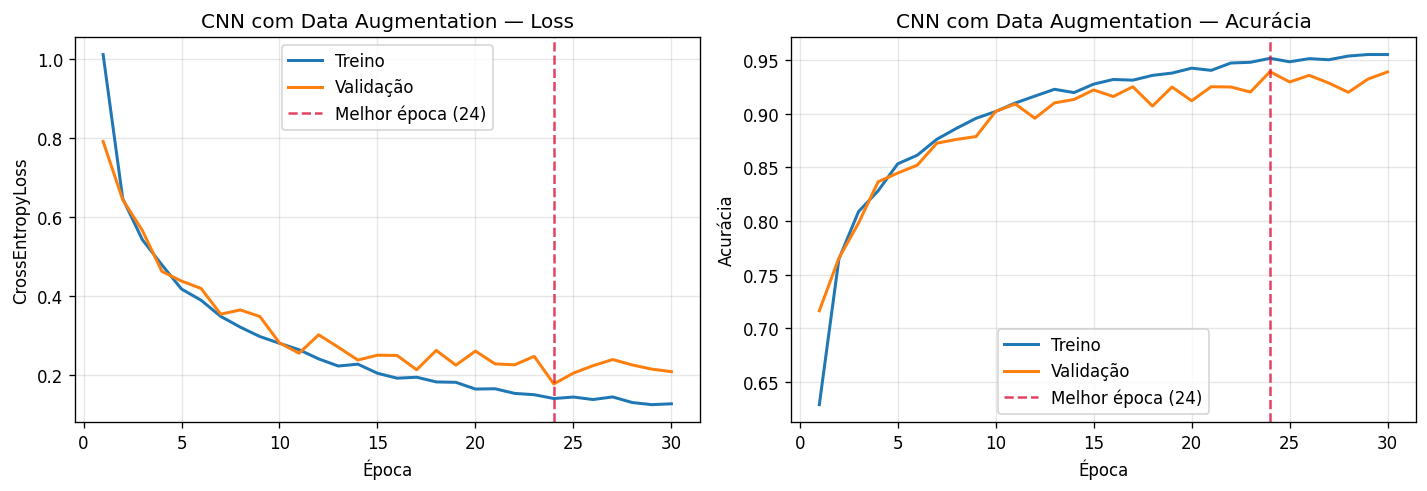

CNN com Data Augmentation -> Acurácia Global: 0.9410 | F1 Macro: 0.9397


,Classe,Precisão,Recall,F1-score
0,AnnualCrop,0.9460,0.8956,0.9201
1,Forest,0.9427,0.9867,0.9642
2,HerbaceousVegetation,0.9362,0.8800,0.9072
3,Highway,0.9479,0.9227,0.9351
4,Industrial,0.9701,0.9520,0.9610
5,Pasture,0.9272,0.9333,0.9302
6,PermanentCrop,0.8527,0.9413,0.8948
7,Residential,0.9758,0.9867,0.9812
8,River,0.9127,0.9200,0.9163
9,SeaLake,0.9888,0.9844,0.9866


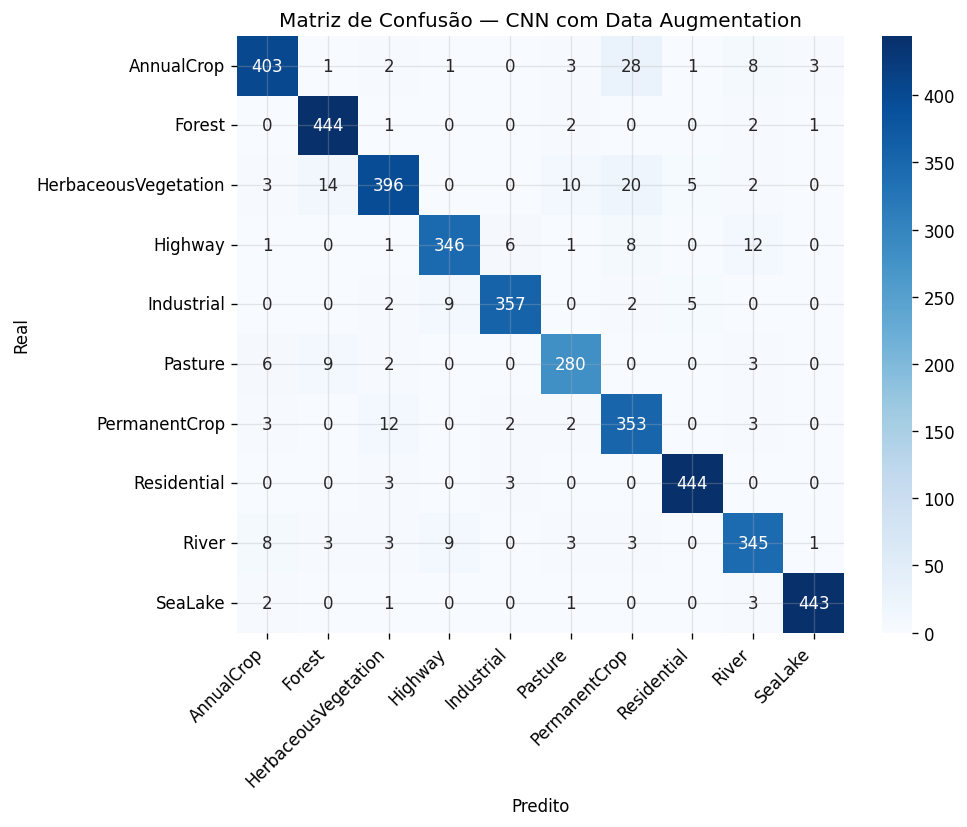

,Modelo,Melhor Época,Menor Val Loss,Gap Loss (Ép. 30),Gap Acc (Ép. 30),Acc Teste,F1 Macro Teste
0,Sem Data Augmentation,6,0.3632,0.8367,0.1288,0.8909,0.8877
1,Com Data Augmentation,24,0.1777,0.0815,0.0162,0.9410,0.9397



Comparação nos 3 pares mais confundidos (modelo base vs. com augmentation):
  HerbaceousVegetation <-> PermanentCrop: 60 -> 32 erros (delta = -28)
  Highway <-> River: 40 -> 21 erros (delta = -19)
  Highway <-> PermanentCrop: 30 -> 8 erros (delta = -22)


In [7]:
tr_loader_aug, va_loader, te_loader = make_loaders(aug_tf)
model_aug, hist_aug, best_ep_aug, best_val_aug = train_cnn(tr_loader_aug, va_loader, epochs=30, lr=1e-3, tag="Com Aug")
plot_curves(hist_aug, best_ep_aug, "CNN com Data Augmentation")
res_aug = evaluate_test(model_aug, te_loader, "CNN com Data Augmentation")

# Comparação consolidada
gap_loss_base = hist_base["va_loss"][-1] - hist_base["tr_loss"][-1]
gap_loss_aug = hist_aug["va_loss"][-1] - hist_aug["tr_loss"][-1]
gap_acc_base = hist_base["tr_acc"][-1] - hist_base["va_acc"][-1]
gap_acc_aug = hist_aug["tr_acc"][-1] - hist_aug["va_acc"][-1]

comp_df = pd.DataFrame([
    {
        "Modelo": "Sem Data Augmentation",
        "Melhor Época": best_ep_base,
        "Menor Val Loss": best_val_base,
        "Gap Loss (Ép. 30)": gap_loss_base,
        "Gap Acc (Ép. 30)": gap_acc_base,
        "Acc Teste": res_base["acc"],
        "F1 Macro Teste": res_base["f1_macro"],
    },
    {
        "Modelo": "Com Data Augmentation",
        "Melhor Época": best_ep_aug,
        "Menor Val Loss": best_val_aug,
        "Gap Loss (Ép. 30)": gap_loss_aug,
        "Gap Acc (Ép. 30)": gap_acc_aug,
        "Acc Teste": res_aug["acc"],
        "F1 Macro Teste": res_aug["f1_macro"],
    },
])
display(comp_df.round(4))

print("\nComparação nos 3 pares mais confundidos (modelo base vs. com augmentation):")
cm_aug = res_aug["cm"]
for total_err, c1, c2, _, _, i1, i2 in top3_pairs:
    err_aug = int(cm_aug[i1, i2] + cm_aug[i2, i1])
    print(f"  {c1} <-> {c2}: {total_err} -> {err_aug} erros (delta = {err_aug - total_err:+d})")